In [93]:
import sys
sys.path.append("../..")
import importlib
import clean_data

importlib.reload(clean_data)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path 
from catboost import CatBoostClassifier, Pool 

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss, f1_score, balanced_accuracy_score, accuracy_score

from clean_data import feature_engineering_days

In [94]:
df = pd.read_csv("../../data/austin/raw/aac_intakes.csv")
outcomes = pd.read_csv("../../data/austin/raw/aac_intakes_outcomes.csv")

df["datetime"] = pd.to_datetime(df["datetime"])
outcomes["intake_datetime"] = pd.to_datetime(outcomes["intake_datetime"])

df = df.merge(
    outcomes[["animal_id_intake", "intake_datetime", "time_in_shelter_days"]],
    left_on=["animal_id", "datetime"],
    right_on=["animal_id_intake", "intake_datetime"],
    how="inner"
)

df = df[df["animal_type"] == "Cat"].copy()

In [95]:
df = feature_engineering_days(df)

df_cats = df[df["animal_type"] == "Cat"].copy()
df_cats = df_cats.sort_values("intake_datetime").reset_index(drop=True)

bins = [-np.inf, 4, 10, np.inf]
df_cats["target"] = pd.cut(
    df_cats["time_in_shelter_days"], bins=bins, labels=[0, 1, 2]
).astype(int)

In [96]:
drop_cols = [
    "target", "time_in_shelter_days", "time_in_shelter",
    "outcome_type", "outcome_subtype", "sex_upon_outcome",
    "intake_datetime", "animal_type", "young_and_cat", "datetime", "animal_id_intake"
]

X = df_cats.drop(columns=drop_cols, errors="ignore")
y = df_cats["target"]

#categorical features which will be available
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
X[cat_features] = X[cat_features].fillna("Unknown").astype(str)

#70/15/15
n = len(X)
i1, i2 = int(n * 0.70), int(n * 0.85)

X_train, X_val, X_test = X.iloc[:i1], X.iloc[i1:i2], X.iloc[i2:]
y_train, y_val, y_test = y.iloc[:i1], y.iloc[i1:i2], y.iloc[i2:]

print("Split:", len(X_train), len(X_val), len(X_test))

Split: 20526 4399 4399


In [97]:
model = CatBoostClassifier(
    iterations=1200, learning_rate=0.03, depth=6,
    loss_function="MultiClass", random_seed=42, verbose=100
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	learn: 1.0799878	test: 1.0821649	best: 1.0821649 (0)	total: 98.3ms	remaining: 1m 57s
100:	learn: 0.7275536	test: 0.8130394	best: 0.8130394 (100)	total: 10.3s	remaining: 1m 52s
200:	learn: 0.7012655	test: 0.8106786	best: 0.8101830 (162)	total: 20.8s	remaining: 1m 43s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.810183002
bestIteration = 162

Shrink model to first 163 iterations.


CatBoostClassifier(depth=6, iterations=1200, learning_rate=0.03, loss_function='MultiClass', random_seed=42, verbose=100)

In [98]:
X_train.columns

Index(['breed', 'color', 'intake_condition', 'intake_type', 'name',
       'previous_intakes', 'is_repeat', 'intake_hour', 'month_sin',
       'month_cos', 'sex', 'intact', 'is_mixed_breed', 'primary_breed',
       'is_mixed_color', 'primary_color', 'has_name', 'name_length',
       'age_days', 'day_of_week', 'month', 'year', 'is_weekend', 'is_puppy',
       'is_senior', 'age_log', 'puppy_and_intact', 'stray_and_intact',
       'breed_age'],
      dtype='object')

# Evaluation


In [99]:
probs = model.predict_proba(X_test)
y_pred = model.classes_[np.argmax(probs, axis=1)]

#Log Loss
ll = log_loss(y_test, probs, labels=model.classes_)

#Multiclass Brier Score
y_onehot = (
    np.asarray(y_test)[:, None]
    == np.asarray(model.classes_)[None, :]
).astype(int)

brier = np.mean(np.sum((probs - y_onehot) ** 2, axis=1))

#Macro F1
f1 = f1_score(y_test, y_pred, average="macro")

#Balanced Accuracy
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"Log Loss:          {ll:.4f}")
print(f"Brier Score:       {brier:.4f}")
print(f"Macro F1:          {f1:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Log Loss:          0.8952
Brier Score:       0.5387
Macro F1:          0.5117
Balanced Accuracy: 0.5397

Classification report:
              precision    recall  f1-score   support

           0       0.52      0.57      0.55      1330
           1       0.56      0.20      0.30      1373
           2       0.59      0.84      0.69      1696

    accuracy                           0.56      4399
   macro avg       0.56      0.54      0.51      4399
weighted avg       0.56      0.56      0.52      4399



In [100]:
from sklearn.metrics import precision_recall_curve, average_precision_score

classes = list(model.classes_)
i2 = classes.index(2)

p2_val = model.predict_proba(X_val)[:, i2]
p2_test = model.predict_proba(X_test)[:, i2]

# Wybór progu na walidacji: najwyższa precyzja przy recall >= 0.6
prec, rec, thr = precision_recall_curve((y_val == 2).astype(int), p2_val)
ok = rec[:-1] >= 0.8
threshold = thr[ok][np.argmax(prec[:-1][ok])]
print(f"Próg dla klasy >30 dni: {threshold:.3f}")

# Ocena na teście
flag = p2_test >= threshold
y_long = (y_test == 2).astype(int)
tp = np.sum(flag & (y_long == 1))
print(f"Oznaczone: {flag.mean():.1%} zwierząt")
print(f"Precyzja: {tp / max(flag.sum(), 1):.3f}")
print(f"Recall:   {tp / y_long.sum():.3f}")
print(f"PR-AUC (klasa >30): {average_precision_score(y_long, p2_test):.3f}")

Próg dla klasy >30 dni: 0.446
Oznaczone: 47.9% zwierząt
Precyzja: 0.642
Recall:   0.798
PR-AUC (klasa >30): 0.721


In [101]:
def predict_dog(model, cat):
    probs = model.predict_proba(cat)[0]

    return pd.DataFrame({
        "Czas pobytu": ["≤7 dni", "7–30 dni", ">30 dni"],
        "Prawdopodobieństwo (%)": [
            round(probs[list(model.classes_).index(i)] * 100, 2)
            for i in [0, 1, 2]
        ]
    })


In [102]:
cat = X_test.iloc[[5]]
print(df_cats.loc[cat.index[0], "time_in_shelter_days"])
display(predict_dog(model, cat))

9.135416666666666


,Czas pobytu,Prawdopodobieństwo (%)
0,≤7 dni,31.64
1,7–30 dni,46.25
2,>30 dni,22.11


In [103]:
cat = X_test.iloc[[30]]

print(df_cats.loc[cat.index[0], "time_in_shelter_days"])

display(predict_dog(model, cat))

9.901388888888889


,Czas pobytu,Prawdopodobieństwo (%)
0,≤7 dni,34.49
1,7–30 dni,25.67
2,>30 dni,39.83


In [104]:
long_stay = X_test[df_cats.loc[X_test.index, "time_in_shelter_days"] > 60]

cat = long_stay.iloc[[0]]

print(df_cats.loc[cat.index[0], "time_in_shelter_days"])
display(predict_dog(model, cat))


62.07986111111112


,Czas pobytu,Prawdopodobieństwo (%)
0,≤7 dni,4.85
1,7–30 dni,11.47
2,>30 dni,83.68


In [105]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss

# Log Loss Twojego modelu
model_probs = model.predict_proba(X_test)
model_log_loss = log_loss(y_test, model_probs)

# Model bazowy
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)

baseline_probs = dummy.predict_proba(X_test)
baseline_log_loss = log_loss(y_test, baseline_probs)

# Log Loss Skill Score
log_loss_skill = 1 - model_log_loss / baseline_log_loss

print(f"Model Log Loss:    {model_log_loss:.4f}")
print(f"Baseline Log Loss: {baseline_log_loss:.4f}")
print(f"Log Loss Skill:    {log_loss_skill:.4f}")
print(f"Improvement:       {log_loss_skill:.2%}")

Model Log Loss:    0.8952
Baseline Log Loss: 1.1309
Log Loss Skill:    0.2085
Improvement:       20.85%


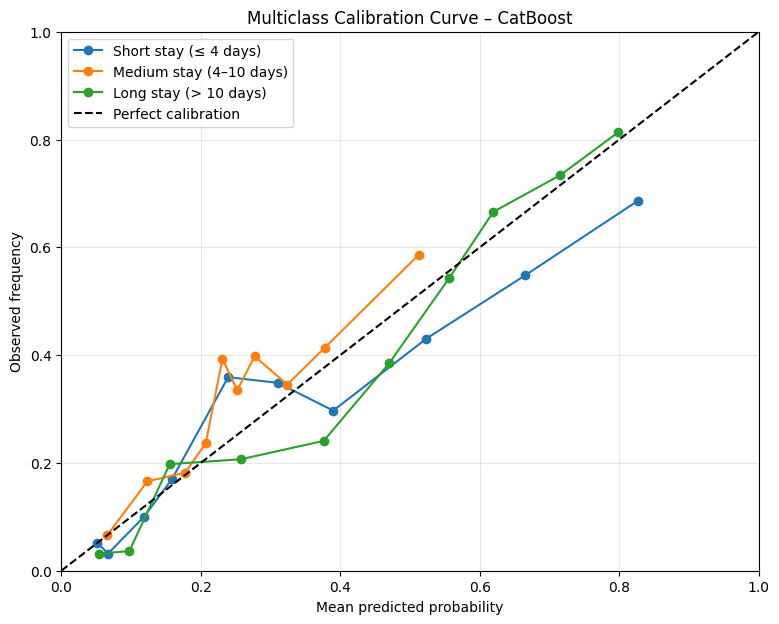

In [106]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

y_proba = model.predict_proba(X_test)

class_names = [
    "Short stay (≤ 4 days)",
    "Medium stay (4–10 days)",
    "Long stay (> 10 days)"
]

plt.figure(figsize=(9, 7))

for i, cls in enumerate(model.classes_):
    prob_true, prob_pred = calibration_curve(
        (y_test == cls).astype(int),
        y_proba[:, i],
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=class_names[i]
    )

plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed frequency")
plt.title("Multiclass Calibration Curve – CatBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

In [107]:
# import shap

# explainer = shap.TreeExplainer(model)
# X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
# shap_values = explainer(X_sample)

# print(shap_values.values.shape)

In [108]:
# class_idx = list(model.classes_).index(2)
# shap_long = shap_values[:, :, class_idx]
# shap.plots.beeswarm(shap_long, max_display=15)

In [109]:
# cat = X_test.iloc[[0]]
# display(predict_dog(model, cat))

# dog_shap = explainer(cat)

# shap.plots.waterfall(
#      dog_shap[0, :, class_idx],
#      max_display=15
#  )